In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.ofc_chords as ofc
import EFC_learningfMRI.behaviour as behav

base directory found: /cifs/diedrichsen/data/Chord_exp/EFC_learningfMRI
Atlas directory found: atlases
figure directory found: figures/


In [2]:
chords = ofc.make_chords()
x_c = ofc.chords_to_targets(chords, flex_force=3.0, ext_force=3.0)

x_c

{np.int64(11911): array([3., 3., 0., 3., 3.]),
 np.int64(12129): array([ 3., -3.,  3., -3.,  0.]),
 np.int64(12291): array([ 3., -3., -3.,  0.,  3.]),
 np.int64(21291): array([-3.,  3., -3.,  0.,  3.]),
 np.int64(21911): array([-3.,  3.,  0.,  3.,  3.]),
 np.int64(22911): array([-3., -3.,  0.,  3.,  3.]),
 np.int64(91211): array([ 0.,  3., -3.,  3.,  3.]),
 np.int64(92122): array([ 0., -3.,  3., -3., -3.])}

In [3]:
E_flex = ofc.make_enslaving(spread=0.5)
E_ext = ofc.make_enslaving(spread=0.6)

E = { 'flex': E_flex,
    'ext': E_ext
}

E

{'flex': array([[1.        , 0.5       , 0.18393972, 0.06766764, 0.02489353],
        [0.5       , 1.        , 0.5       , 0.18393972, 0.06766764],
        [0.18393972, 0.5       , 1.        , 0.5       , 0.18393972],
        [0.06766764, 0.18393972, 0.5       , 1.        , 0.5       ],
        [0.02489353, 0.06766764, 0.18393972, 0.5       , 1.        ]]),
 'ext': array([[1.        , 0.6       , 0.22072766, 0.08120117, 0.02987224],
        [0.6       , 1.        , 0.6       , 0.22072766, 0.08120117],
        [0.22072766, 0.6       , 1.        , 0.6       , 0.22072766],
        [0.08120117, 0.22072766, 0.6       , 1.        , 0.6       ],
        [0.02987224, 0.08120117, 0.22072766, 0.6       , 1.        ]])}

In [ ]:
# Set global experiment parameters

rng = np.random.default_rng(seed=0)

n_steps = int(2 * gl.fsample['force'])  # trial duration (3.5 s)
delay = int(.1 * gl.fsample['force'])  # sensory delay in samples (20 ms)
tau = .03  # time constant of the plant (30 ms)

# init plant
plant = ofc.Plant(E_flex=E['flex'], E_ext=E['ext'], delay=delay, dt = 1 / gl.fsample['force'], tau=tau, motor_sdn=0.2)

# init internal model (no enslavement assumed)
internal_model = ofc.initial_model(plant)

A0 = internal_model.A_hat
B0 = internal_model.B_hat

Q = np.eye(plant.n)                      # one weight per finger
R = plant.gain ** 2 * np.eye(plant.m)    # one weight per command; plant.gain = dt / tau = b

trained_untrained = list(gl.chordID)

rows = []

tot_TN = 0
tot_BN = 0

# Testing (T0)

In [5]:
n_trial = 16
n_block = 5

chordID = np.tile(np.array(trained_untrained), n_trial // len(trained_untrained))

for BN in range(n_block):
    for TN in range(n_trial):
        controller     = ofc.design_controller(internal_model, plant, x_c[chordID[TN]], Q, R)
        trial          = ofc.simulate_trial(plant, controller, n_steps, rng)
        internal_model = ofc.update_model(internal_model, trial, plant)

        F = trial['x']
        F = np.r_[np.zeros((int(gl.plan_time * gl.fsample['force']), plant.n)), F]

        trial_dict = behav.analyse_trial(F, chordID[TN])

        tot_TN += 1

        row = {
            'TN'          : tot_TN,
            'BN'         : tot_BN,
            'trialPoint'  : trial_dict['trialPoint'],
            'RT'          : trial_dict['RT'],
            'ET'          : trial_dict['ET'],
            'MD'          : trial_dict['MD'],
            'chordID'     : chordID[TN],
            'chord'       : 'trained' if trained_untrained.index(chordID[TN]) < 4 else 'untrained',
            'session'     : 'T0'
        }
        for i, f in enumerate(gl.fingers):
            row[f'{f}_raw'] = trial_dict['F_avg'][i]
            row[f'{f}_abs'] = trial_dict['F_abs_avg'][i]
            row[f'{f}_der'] = trial_dict['F_der_abs_avg'][i]

        rows.append(row)

    tot_BN += 1
    

# Training

In [ ]:
n_trial = 64
n_block = 100

chordID = np.tile(np.array(trained_untrained[:4]), n_trial // len(trained_untrained[:4]))

for BN in range(n_block):
    for TN in range(n_trial):
        controller     = ofc.design_controller(internal_model, plant, x_c[chordID[TN]], Q, R)
        trial          = ofc.simulate_trial(plant, controller, n_steps, rng)
        internal_model = ofc.update_model(internal_model, trial, plant)

        F = trial['x']
        F = np.r_[np.zeros((int(gl.plan_time * gl.fsample['force']), plant.n)), F]

        trial_dict = behav.analyse_trial(F, chordID[TN])

        tot_TN += 1


        row = {
            'TN'          : tot_TN,
            'BN'         : tot_BN,
            'trialPoint'  : trial_dict['trialPoint'],
            'RT'          : trial_dict['RT'],
            'ET'          : trial_dict['ET'],
            'MD'          : trial_dict['MD'],
            'chordID'     : chordID[TN],
            'chord'       : 'trained' if trained_untrained.index(chordID[TN]) < 4 else 'untrained',
            'session'     : 'training'
        }
        for i, f in enumerate(gl.fingers):
            row[f'{f}_raw'] = trial_dict['F_avg'][i]
            row[f'{f}_abs'] = trial_dict['F_abs_avg'][i]
            row[f'{f}_der'] = trial_dict['F_der_abs_avg'][i]

        rows.append(row)

    tot_BN += 1

In [ ]:
n_trial = 16
n_block = 5

chordID = np.tile(np.array(trained_untrained), n_trial // len(trained_untrained))

for BN in range(n_block):
    for TN in range(n_trial):
        controller     = ofc.design_controller(internal_model, plant, x_c[chordID[TN]], Q, R)
        trial          = ofc.simulate_trial(plant, controller, n_steps, rng)
        internal_model = ofc.update_model(internal_model, trial, plant)

        F = trial['x']
        F = np.r_[np.zeros((int(gl.plan_time * gl.fsample['force']), plant.n)), F]

        trial_dict = behav.analyse_trial(F, chordID[TN])

        tot_TN += 1

        row = {
            'TN'          : tot_TN,
            'BN'         : tot_BN,
            'trialPoint'  : trial_dict['trialPoint'],
            'RT'          : trial_dict['RT'],
            'ET'          : trial_dict['ET'],
            'MD'          : trial_dict['MD'],
            'chordID'     : chordID[TN],
            'chord'       : 'trained' if trained_untrained.index(chordID[TN]) < 4 else 'untrained',
            'session'     : 'T1'
        }
        for i, f in enumerate(gl.fingers):
            row[f'{f}_raw'] = trial_dict['F_avg'][i]
            row[f'{f}_abs'] = trial_dict['F_abs_avg'][i]
            row[f'{f}_der'] = trial_dict['F_der_abs_avg'][i]

        rows.append(row)

    tot_BN += 1

In [ ]:
df = pd.DataFrame(rows)

# long format: one row per trial x finger, with separate columns for raw, abs and der
id_cols = ['TN', 'BN', 'trialPoint', 'RT', 'ET', 'MD', 'chordID', 'chord', 'session']
df = pd.concat([df[id_cols].assign(finger=f,
                                   force_raw=df[f'{f}_raw'],
                                   force_abs=df[f'{f}_abs'],
                                   force_der=df[f'{f}_der'])
                for f in gl.fingers], ignore_index=True)

df_g = df.groupby(['BN', 'chord', 'session', 'finger']).mean(numeric_only=True).reset_index()

<Axes: xlabel='session', ylabel='force_abs'>

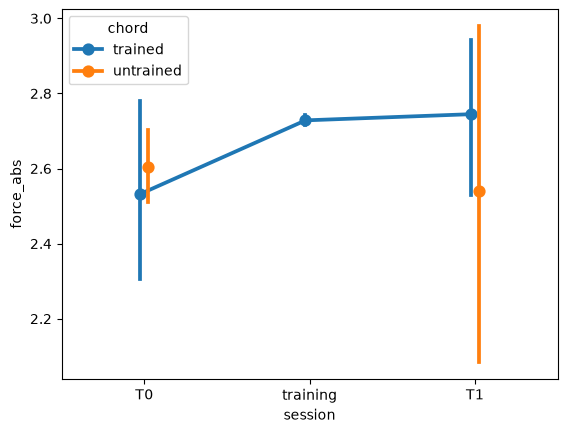

In [ ]:
sb.pointplot(data=df[df.finger == 'index'], x='session', y='force_abs', hue='chord', dodge=True)

<Axes: xlabel='session', ylabel='force_der'>

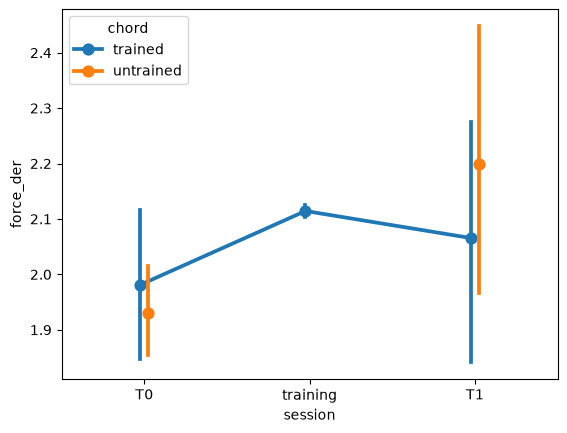

In [ ]:
sb.pointplot(data=df[df.finger == 'index'], x='session', y='force_der', hue='chord', dodge=True)